# Predicting Goals Scored per Football Match using Poisson and Negative Binomial Regression

**Course:** Predictive Analytics (B.Tech CS)

This project uses five distinct English Premier League seasons supplied as CSV files. Four complete seasons (2022-23 through 2025-26) are used for training; the currently available 80 matches from 2026-27 form the chronological test set. The 2026-27 file contains fixtures from August to October 2026, so its season label is assigned from the football-season context rather than the calendar year alone.

## 1. Introduction and analytics context

- **Descriptive analytics:** summarizes historical goals, venue differences and team scoring.
- **Predictive analytics:** estimates expected goals for a team in a future match.
- **Prescriptive analytics:** can use forecasts to inform training, tactical planning or squad decisions.
- Football analytics supports clubs, media and performance analysis. Predictions are uncertain; they should not be framed as guarantees or gambling advice.

Goals are non-negative integer counts. A Poisson or Negative Binomial GLM is more appropriate than assuming a continuous, constant-variance response as in ordinary linear regression.

In [1]:

import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
from collections import defaultdict, deque
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import scipy.stats as st
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_poisson_deviance, accuracy_score, log_loss
from sklearn.linear_model import PoissonRegressor, LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
import joblib
DATA=Path("data")
season_files={"2022-23":"E0_202223.csv","2023-24":"E0_202324.csv","2024-25":"E0_202425.csv",
              "2025-26":"E0_202526.csv","2026-27":"E0_202627.csv"}


## 2. Data collection, validation and preprocessing

The source files contain full-time home and away goals, teams, match dates and additional match statistics. Required fields are checked, dates parsed day-first, goals converted to non-negative integers and duplicate fixtures removed. Team names are preserved as supplied.

In [2]:

parts=[]
for season,fn in season_files.items():
    d=pd.read_csv(DATA/fn)
    d["Date"]=pd.to_datetime(d["Date"],dayfirst=True,errors="coerce")
    d["Season"]=season
    parts.append(d)
matches=pd.concat(parts,ignore_index=True).drop_duplicates(["Date","HomeTeam","AwayTeam"])
required=["Date","HomeTeam","AwayTeam","FTHG","FTAG","FTR"]
print("Missing required fields:\n",matches[required].isna().sum())
matches=matches.dropna(subset=required).copy()
matches["FTHG"]=pd.to_numeric(matches.FTHG,errors="coerce")
matches["FTAG"]=pd.to_numeric(matches.FTAG,errors="coerce")
matches=matches.dropna(subset=["FTHG","FTAG"])
matches=matches[(matches.FTHG>=0)&(matches.FTAG>=0)].copy()
matches["FTHG"]=matches.FTHG.astype(int); matches["FTAG"]=matches.FTAG.astype(int)
matches=matches.sort_values(["Date","Time"]).reset_index(drop=True)
matches["MatchID"]=np.arange(len(matches))
print("Season counts:",matches.groupby("Season").size().to_dict())
print("Total matches:",len(matches))


Missing required fields:
 Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
dtype: int64
Season counts: {'2022-23': 380, '2023-24': 380, '2024-25': 380, '2025-26': 380, '2026-27': 80}
Total matches: 1600


## 3. Exploratory data analysis

The plots compare home/away goal distributions, scoring by season, team attack/defence averages and correlations with match statistics. Correlation is descriptive, not causal. Post-match shots are not included as pre-match predictors because they would leak information.

Average total goals: 2.945
Home mean: 1.613125 Away mean: 1.331875


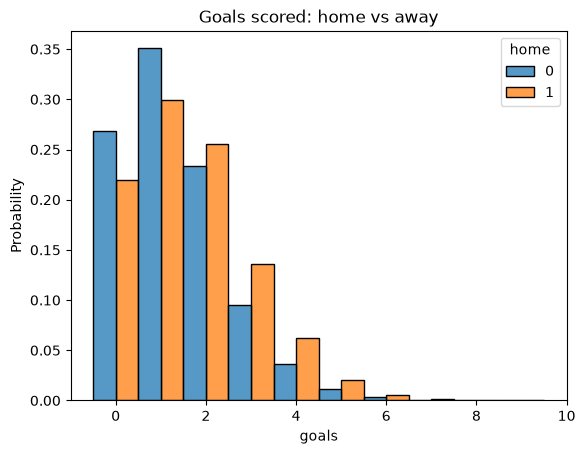

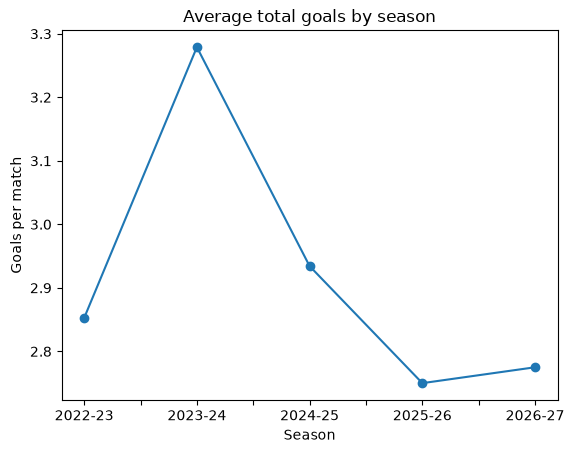

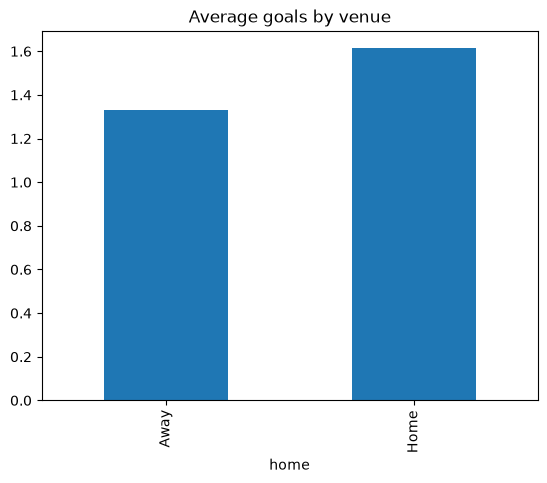

In [3]:

long0=pd.concat([
 matches.assign(team=matches.HomeTeam,opponent=matches.AwayTeam,home=1,goals=matches.FTHG),
 matches.assign(team=matches.AwayTeam,opponent=matches.HomeTeam,home=0,goals=matches.FTAG)
],ignore_index=True)
print("Average total goals:",(matches.FTHG+matches.FTAG).mean())
print("Home mean:",matches.FTHG.mean(),"Away mean:",matches.FTAG.mean())
sns.histplot(data=long0,x="goals",hue="home",discrete=True,multiple="dodge",stat="probability",common_norm=False)
plt.title("Goals scored: home vs away"); plt.show()
matches.assign(total=matches.FTHG+matches.FTAG).groupby("Season").total.mean().plot(marker="o")
plt.title("Average total goals by season"); plt.ylabel("Goals per match"); plt.show()
long0.groupby("home").goals.mean().rename(index={0:"Away",1:"Home"}).plot.bar(title="Average goals by venue")
plt.show()


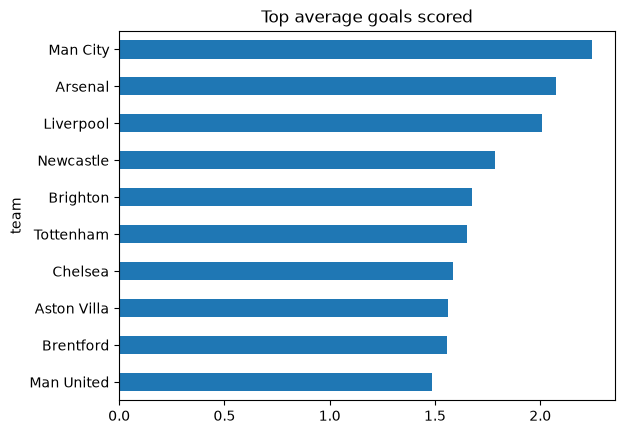

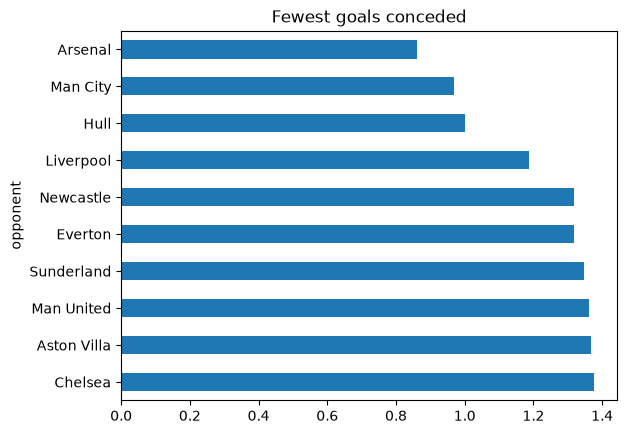

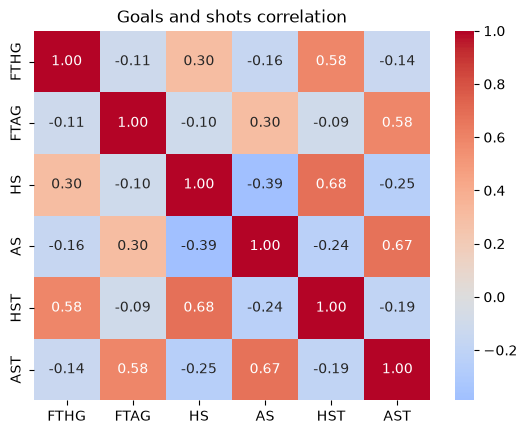

In [4]:

attack=long0.groupby("team").goals.mean().sort_values(ascending=False)
defence=long0.groupby("opponent").goals.mean().sort_values()
attack.head(10).sort_values().plot.barh(title="Top average goals scored"); plt.show()
defence.head(10).sort_values(ascending=False).plot.barh(title="Fewest goals conceded"); plt.show()
cols=[c for c in ["FTHG","FTAG","HS","AS","HST","AST"] if c in matches]
sns.heatmap(matches[cols].corr(numeric_only=True),annot=True,fmt=".2f",cmap="coolwarm",center=0)
plt.title("Goals and shots correlation"); plt.show()


## 4. Feature engineering and leakage prevention

Each fixture becomes two team-perspective observations. Predictors are team, opponent, home indicator, previous-five-match scoring form and opponent's previous-five-match conceding form. Rolling histories are updated only after both rows for the current match are created, so the current result cannot leak into its own features.

In [5]:

sc=defaultdict(lambda:deque(maxlen=5)); co=defaultdict(lambda:deque(maxlen=5)); rows=[]
for r in matches.itertuples(index=False):
 h,a=r.HomeTeam,r.AwayTeam
 rows.extend([
  dict(Date=r.Date,Season=r.Season,MatchID=r.MatchID,team=h,opponent=a,home=1,goals=r.FTHG,
       form_scored=np.mean(sc[h]) if sc[h] else np.nan,
       form_conceded=np.mean(co[a]) if co[a] else np.nan,FTR=r.FTR),
  dict(Date=r.Date,Season=r.Season,MatchID=r.MatchID,team=a,opponent=h,home=0,goals=r.FTAG,
       form_scored=np.mean(sc[a]) if sc[a] else np.nan,
       form_conceded=np.mean(co[h]) if co[h] else np.nan,FTR=r.FTR)])
 sc[h].append(r.FTHG); co[h].append(r.FTAG); sc[a].append(r.FTAG); co[a].append(r.FTHG)
long=pd.DataFrame(rows)
gm=float(long.goals.mean())
long[["form_scored","form_conceded"]]=long[["form_scored","form_conceded"]].fillna(gm)


## 5. Poisson distribution and GLM

For a count response \(Y\), the Poisson probability mass function is:

\[
P(Y=y)=\frac{e^{-\lambda}\lambda^y}{y!},\quad E(Y)=Var(Y)=\lambda.
\]

The GLM uses a log link:

\[
\log(\lambda_i)=\beta_0+X_i\beta,\qquad \lambda_i=e^{\beta_0+X_i\beta}.
\]

The log link guarantees positive expected goals. Coefficients are estimated by maximum likelihood. Exponentiating a coefficient gives an incidence rate ratio (IRR); for example, IRR 1.10 corresponds to a 10% increase in expected scoring rate, holding other predictors fixed.

## 6. Chronological split, Poisson fit and coefficient estimation

Four full seasons train the model; the currently available 2026-27 season is held out. Team categories from the test season are included for prediction, but unseen clubs receive the reference-team effect because no historical team-specific evidence exists.

In [6]:

seasons=["2022-23","2023-24","2024-25","2025-26","2026-27"]
train=long[long.Season!="2026-27"].copy()
test=long[long.Season=="2026-27"].copy()
train_teams=sorted(set(train.team)|set(train.opponent))
all_teams=sorted(set(train_teams)|set(test.team)|set(test.opponent))
ref="Arsenal" if "Arsenal" in train_teams else train_teams[0]
for d in [train,test]:
 d["team"]=pd.Categorical(d.team,categories=all_teams)
 d["opponent"]=pd.Categorical(d.opponent,categories=all_teams)
formula=f"goals ~ C(team, Treatment(reference='{ref}')) + C(opponent, Treatment(reference='{ref}')) + home + form_scored + form_conceded"
poisson=smf.glm(formula,data=train,family=sm.families.Poisson()).fit()
print(poisson.summary())
irr=np.exp(poisson.params)
print("Home IRR:",irr["home"])


                 Generalized Linear Model Regression Results                  
Dep. Variable:                  goals   No. Observations:                 3040
Model:                            GLM   Df Residuals:                     2988
Model Family:                 Poisson   Df Model:                           51
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -4476.6
Date:                Mon, 02 Nov 2026   Deviance:                       3248.2
Time:                        14:03:12   Pearson chi2:                 2.79e+03
No. Iterations:                   100   Pseudo R-squ. (CS):             0.1497
Covariance Type:            nonrobust                                         
                                                                      coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


## 7. Overdispersion and Negative Binomial regression

Poisson assumes conditional variance equals conditional mean. Variance/mean and Pearson chi-square per residual degree of freedom are diagnostics. The NB2 model adds a dispersion parameter α with variance approximately μ + αμ². Here α is estimated by the method of moments to keep the comparison identifiable even when some test-season clubs have no training observations.

In [7]:

ratio=float(train.goals.var()/train.goals.mean())
pearson=float(poisson.pearson_chi2/poisson.df_resid)
alpha=max(float((train.goals.var()-train.goals.mean())/(train.goals.mean()**2)),1e-8)
nb=smf.glm(formula,data=train,family=sm.families.NegativeBinomial(alpha=alpha)).fit()
print("Variance/mean:",ratio,"Pearson dispersion:",pearson,"NB alpha:",alpha)
print("Poisson AIC:",poisson.aic,"NB AIC:",nb.aic)


Variance/mean: 1.0788377667897144 Pearson dispersion: 0.9352629252516669 NB alpha: 0.05337790891775761
Poisson AIC: 9057.127713323482 NB AIC: 9085.798420663454


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


## 8. Test-set evaluation and baseline models

The 2026-27 test set currently contains 80 matches (160 team-match observations). Metrics are RMSE, MAE and mean Poisson deviance. Linear regression and the training-mean baseline provide reference comparisons.

In [8]:

features=["team","opponent","home","form_scored","form_conceded"]
Xtr=train[features].astype({"team":str,"opponent":str})
Xte=test[features].astype({"team":str,"opponent":str})
y=test.goals.to_numpy()
pp=np.maximum(poisson.predict(test),1e-8)
pn=np.maximum(nb.predict(test),1e-8)
lin=Pipeline([("prep",ColumnTransformer([
 ("cat",OneHotEncoder(handle_unknown="ignore"),["team","opponent"]),
 ("num","passthrough",["home","form_scored","form_conceded"])])),
 ("model",LinearRegression())]).fit(Xtr,train.goals)
pl=lin.predict(Xte)
def met(y,p):
 return [np.sqrt(mean_squared_error(y,p)),mean_absolute_error(y,p),
         mean_poisson_deviance(y,np.maximum(p,1e-8))]
results=pd.DataFrame([met(y,pp),met(y,pn),met(y,np.full(len(y),train.goals.mean())),met(y,pl)],
 index=["Poisson GLM","Negative Binomial GLM","Training mean","Linear regression"],
 columns=["RMSE","MAE","Mean Poisson deviance"])
display(results)


,RMSE,MAE,Mean Poisson deviance
Poisson GLM,1.245268,1.001586,1.304346
Negative Binomial GLM,1.245207,1.001511,1.304277
Training mean,1.253136,1.034046,1.309336
Linear regression,1.220894,0.986550,1.271462


## 9. Temporal validation, regularization and prediction

TimeSeriesSplit keeps validation folds later than their training folds. L2 regularization shrinks large coefficients and can improve generalization. The selected regularized Poisson pipeline is saved for the Streamlit application.

In [9]:

ordered=train.sort_values(["Date","MatchID","home"])
Xcv=ordered[features].astype({"team":str,"opponent":str}); ycv=ordered.goals.to_numpy()
pre=ColumnTransformer([("cat",OneHotEncoder(handle_unknown="ignore"),["team","opponent"]),
 ("num","passthrough",["home","form_scored","form_conceded"])])
cvrows=[]
for a in [.001,.01,.1,1.,10.]:
 vals=[]
 for ix,vx in TimeSeriesSplit(n_splits=4).split(Xcv):
  p=Pipeline([("prep",pre),("model",PoissonRegressor(alpha=a,max_iter=1500))]).fit(Xcv.iloc[ix],ycv[ix])
  vals.append(mean_poisson_deviance(ycv[vx],np.maximum(p.predict(Xcv.iloc[vx]),1e-8)))
 cvrows.append({"alpha":a,"validation_deviance":np.mean(vals)})
cv_table=pd.DataFrame(cvrows); display(cv_table)
best_alpha=float(cv_table.loc[cv_table.validation_deviance.idxmin(),"alpha"])
final_model=Pipeline([("prep",pre),("model",PoissonRegressor(alpha=best_alpha,max_iter=2500))]).fit(Xtr,train.goals)
print("Selected alpha:",best_alpha)


,alpha,validation_deviance
0,0.001,1.146312
1,0.010,1.127413
2,0.100,1.121292
3,1.000,1.165210
4,10.000,1.202568


Selected alpha: 0.1


## 10. Conclusion, limitations and ethics

Poisson GLM provides an interpretable count-data baseline. The Negative Binomial comparison tests whether extra variance is needed. The 2026-27 test set is still small and represents only the first 80 matches available in the uploaded file. Promoted clubs with no training-season history are assigned baseline team effects. The model omits injuries, line-ups, transfers, tactical matchups, referee effects and player-level quality. Football is noisy; predictions should be communicated with uncertainty and not presented as guarantees or betting advice. Extensions include Dixon–Coles low-score correction, Elo ratings, xG features, zero-inflated models if excess zeros are demonstrated, and bivariate Poisson models.

In [10]:
# Rebuild the team form lookup required by the app
team_forms = {}

for t in all_teams:
    z = long[long.team.astype(str) == t].sort_values(
        ["Date", "MatchID"]
    )
    team_forms[t] = {
        "form_scored": float(z.form_scored.iloc[-1]),
        "form_conceded": float(z.form_conceded.iloc[-1])
    }

# Save using the current Python environment
bundle = {
    "model": final_model,
    "teams": all_teams,
    "forms": team_forms,
    "alpha": best_alpha
}

joblib.dump(bundle, "football_goal_model.joblib")

print("Model successfully regenerated!")

Model successfully regenerated!
